HIR-HRI-10K: LSTM vs Random Forest — Research Baselines
Reproducible, episode-level comparison using the provided train/validation/test partitions. Each episode is 10 frames (0.2 s sampling); the LSTM sees a 10 × 28 feature sequence and Random Forest sees summary statistics of the same 10 frames. Neither model receives identifiers or labels as features.
Research integrity: These data and labels are synthetic and generated by handcrafted rules. Metrics are synthetic held-out performance, not human-subject or real-world robot performance. No real image or sensor recordings are included. Save all figures as PNG and PDF at 300 dpi.

In [2]:
# Run once in Jupyter if packages are missing:
# %pip install numpy pandas scikit-learn torch matplotlib seaborn
from pathlib import Path
import random, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc,
                             precision_recall_curve, average_precision_score)
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.set_num_threads(min(4, torch.get_num_threads()))
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ROOT=Path.cwd(); DATA=ROOT/'dataset'; FIG=ROOT/'results'/'figures'; FIG.mkdir(parents=True,exist_ok=True)
print('PyTorch:',torch.__version__,'Device:',DEVICE)
sns.set_theme(style='whitegrid', context='paper',font_scale=1.15)
def savefig(name):
    plt.tight_layout(); plt.savefig(FIG/(name+'.png'),dpi=300,bbox_inches='tight'); plt.savefig(FIG/(name+'.pdf'),bbox_inches='tight'); plt.show()


PyTorch: 2.2.2+cu118 Device: cuda


1. Load partitions and verify leakage-safe episodes

In [4]:
train=pd.read_csv('DATA_HIR/hir_multimodal_train.csv')
val=pd.read_csv('DATA_HIR/hir_multimodal_validation.csv')
test=pd.read_csv('DATA_HIR/hir_multimodal_test.csv')
labels=pd.read_csv('DATA_HIR/label_map.csv').sort_values('intention_id')
classes=labels.intention_label.tolist(); K=len(classes)
exclude={'sample_id','episode_id','subject_id','split','frame_index','timestamp_s','intention_id','intention_label'}
features=[c for c in train.columns if c not in exclude]
assert len(features)==28
assert len(train)==7000 and len(val)==1500 and len(test)==1500
assert not (set(train.episode_id)&set(val.episode_id) or set(train.episode_id)&set(test.episode_id) or set(val.episode_id)&set(test.episode_id))
assert not (set(train.subject_id)&set(val.subject_id) or set(train.subject_id)&set(test.subject_id) or set(val.subject_id)&set(test.subject_id))
for d in (train,val,test):
    assert d.groupby('episode_id').size().eq(10).all()
    assert d.groupby('episode_id').intention_id.nunique().eq(1).all()
print('Rows:',len(train),len(val),len(test),'Episodes:',train.episode_id.nunique(),val.episode_id.nunique(),test.episode_id.nunique())
print('Numeric input features:',len(features)); display(labels)

Rows: 7000 1500 1500 Episodes: 700 150 150
Numeric input features: 28


,intention_id,intention_label,episode_count,sample_count
0,0,walking,84,840
1,1,approaching_robot,84,840
2,2,avoiding_robot,84,840
3,3,requesting_assistance,84,840
4,4,object_handover,83,830
5,5,object_pickup,83,830
6,6,following_robot,83,830
7,7,stopping,83,830
8,8,greeting_robot,83,830
9,9,pointing,83,830


2. Exploratory data analysis

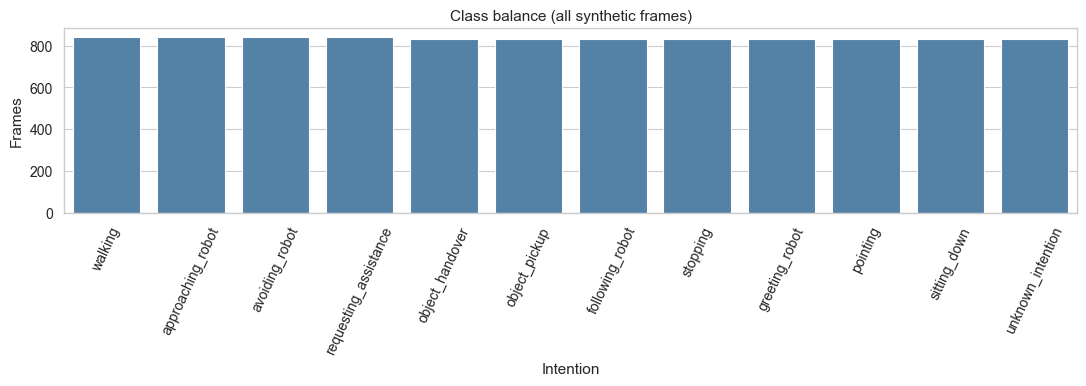

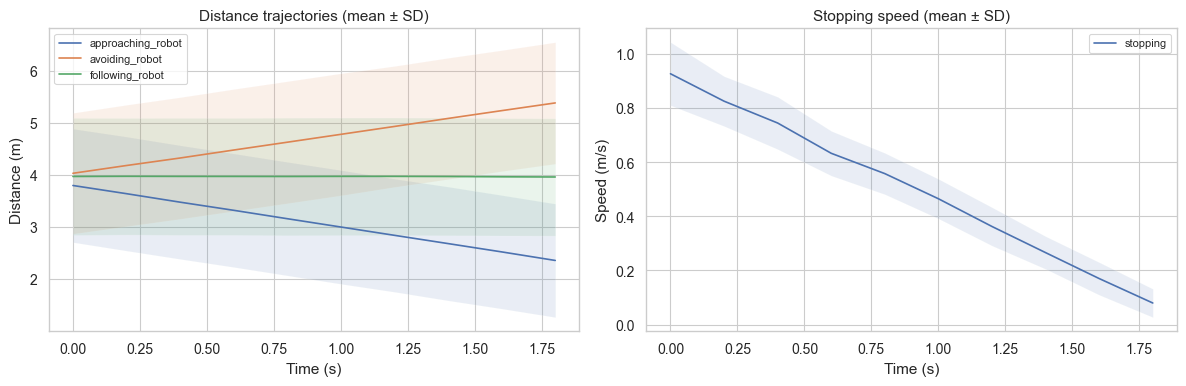

In [6]:
fig,ax=plt.subplots(figsize=(11,4))
sns.countplot(data=pd.concat([train,val,test]),x='intention_label',order=classes,color='steelblue',ax=ax)
ax.set(xlabel='Intention',ylabel='Frames',title='Class balance (all synthetic frames)'); ax.tick_params(axis='x',rotation=65)
savefig('01_class_distribution')
fig,axs=plt.subplots(1,2,figsize=(12,4))
for c in ['approaching_robot','avoiding_robot','following_robot','stopping']:
    subset=train[train.intention_label==c]
    if c=='stopping':
        z=subset.groupby('frame_index').walking_speed_mps.agg(['mean','std']); a=axs[1]
    else:
        z=subset.groupby('frame_index').distance_to_robot_m.agg(['mean','std']); a=axs[0]
    a.plot(z.index*.2,z['mean'],label=c); a.fill_between(z.index*.2,z['mean']-z['std'],z['mean']+z['std'],alpha=.12)
axs[0].set(title='Distance trajectories (mean ± SD)',xlabel='Time (s)',ylabel='Distance (m)')
axs[1].set(title='Stopping speed (mean ± SD)',xlabel='Time (s)',ylabel='Speed (m/s)')
for a in axs:a.legend(fontsize=8)
savefig('02_temporal_patterns')

3. Build independent episode tensors; normalize using TRAIN ONLY

In [8]:
def episodes(df):
    X=[]; y=[]; ids=[]
    for ep,g in df.groupby('episode_id',sort=True):
        g=g.sort_values('frame_index'); X.append(g[features].to_numpy(dtype=np.float32))
        y.append(int(g.intention_id.iloc[0])); ids.append(ep)
    return np.stack(X),np.array(y,dtype=np.int64),ids
Xtr,ytr,idtr=episodes(train); Xva,yva,idva=episodes(val); Xte,yte,idte=episodes(test)
scaler=StandardScaler().fit(Xtr.reshape(-1,len(features)))
def scale(X):return scaler.transform(X.reshape(-1,len(features))).reshape(X.shape).astype(np.float32)
Ztr,Zva,Zte=map(scale,(Xtr,Xva,Xte))
# RF gets aggregate temporal features from exactly the same episodes.
def aggregate(z):return np.concatenate([z.mean(axis=1),z.std(axis=1),z[:,-1,:]-z[:,0,:]],axis=1)
Atr,Ava,Ate=map(aggregate,(Ztr,Zva,Zte))
print('LSTM tensors:',Ztr.shape,Zva.shape,Zte.shape,'RF:',Atr.shape)

LSTM tensors: (700, 10, 28) (150, 10, 28) (150, 10, 28) RF: (700, 84)


4. Random Forest: tune on validation, evaluate test once

In [10]:
rf_runs=[]; best_rf=None; best_rf_score=-1
for depth in [8,None]:
    for leaf in [1,3]:
        rf=RandomForestClassifier(n_estimators=250,max_depth=depth,min_samples_leaf=leaf,
                                  class_weight='balanced_subsample',random_state=SEED,n_jobs=-1)
        rf.fit(Atr,ytr); pred=rf.predict(Ava)
        score=precision_recall_fscore_support(yva,pred,average='macro',zero_division=0)[2]
        rf_runs.append({'max_depth':str(depth),'min_samples_leaf':leaf,'validation_macro_f1':score})
        if score>best_rf_score:best_rf_score=score;best_rf=rf
rf_tuning=pd.DataFrame(rf_runs);display(rf_tuning)
print('Best RF validation macro F1:',round(best_rf_score,4))

,max_depth,min_samples_leaf,validation_macro_f1
0,8,1,0.992409
1,8,3,0.992409
2,None,1,0.992409
3,None,3,0.992409


Best RF validation macro F1: 0.9924


5. LSTM training with validation early stopping

In [12]:
class IntentionLSTM(nn.Module):
    def __init__(self,dim,n_classes,hidden=64,dropout=.25):
        super().__init__()
        self.lstm=nn.LSTM(input_size=dim,hidden_size=hidden,num_layers=1,batch_first=True)
        self.net=nn.Sequential(nn.LayerNorm(hidden),nn.Dropout(dropout),nn.Linear(hidden,32),nn.ReLU(),nn.Linear(32,n_classes))
    def forward(self,x):
        z,_=self.lstm(x);return self.net(z[:,-1,:])
train_loader=DataLoader(TensorDataset(torch.from_numpy(Ztr),torch.from_numpy(ytr)),batch_size=64,shuffle=True)
val_loader=DataLoader(TensorDataset(torch.from_numpy(Zva),torch.from_numpy(yva)),batch_size=128)
model=IntentionLSTM(len(features),K).to(DEVICE)
opt=torch.optim.AdamW(model.parameters(),lr=.002,weight_decay=.001)
criterion=nn.CrossEntropyLoss()
def infer(net,z,batch=128):
    net.eval();out=[]
    with torch.no_grad():
        for i in range(0,len(z),batch):out.append(torch.softmax(net(torch.from_numpy(z[i:i+batch]).to(DEVICE)),dim=1).cpu().numpy())
    return np.concatenate(out)
history=[]; best=-1; best_state=None; patience=10; wait=0; epochs=65
for epoch in range(1,epochs+1):
    model.train();total=0;correct=0;loss_sum=0
    for xb,yb in train_loader:
        xb=xb.to(DEVICE);yb=yb.to(DEVICE)
        opt.zero_grad();logits=model(xb);loss=criterion(logits,yb);loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(),1.0);opt.step()
        loss_sum+=loss.item()*len(yb);correct+=(logits.argmax(1)==yb).sum().item();total+=len(yb)
    pv=infer(model,Zva);pred=pv.argmax(1)
    vf1=precision_recall_fscore_support(yva,pred,average='macro',zero_division=0)[2]
    vloss=criterion(torch.from_numpy(np.log(np.clip(pv,1e-9,1))).float(),torch.from_numpy(yva)).item()
    history.append({'epoch':epoch,'train_loss':loss_sum/total,'train_accuracy':correct/total,
                    'val_loss':vloss,'val_accuracy':accuracy_score(yva,pred),'val_macro_f1':vf1})
    if vf1>best+1e-4:
        best=vf1;best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()};wait=0
    else:wait+=1
    if epoch%5==0 or epoch==1:print(f'Epoch {epoch:02d} | train loss {loss_sum/total:.4f} | val macro F1 {vf1:.4f}')
    if wait>=patience:print('Early stopping at epoch',epoch);break
model.load_state_dict(best_state);model.eval()
hist=pd.DataFrame(history);hist.to_csv(ROOT/'results'/'lstm_training_history.csv',index=False)
print('Best LSTM validation macro F1:',round(best,4))

Epoch 01 | train loss 2.1641 | val macro F1 0.6482
Epoch 05 | train loss 0.2974 | val macro F1 0.9036
Epoch 10 | train loss 0.1438 | val macro F1 0.9441
Epoch 15 | train loss 0.1030 | val macro F1 0.9384
Epoch 20 | train loss 0.0760 | val macro F1 0.9509
Epoch 25 | train loss 0.1078 | val macro F1 0.9530
Epoch 30 | train loss 0.0236 | val macro F1 0.9697
Epoch 35 | train loss 0.0283 | val macro F1 0.9601
Early stopping at epoch 39
Best LSTM validation macro F1: 0.9772


6. Training curves (LSTM)

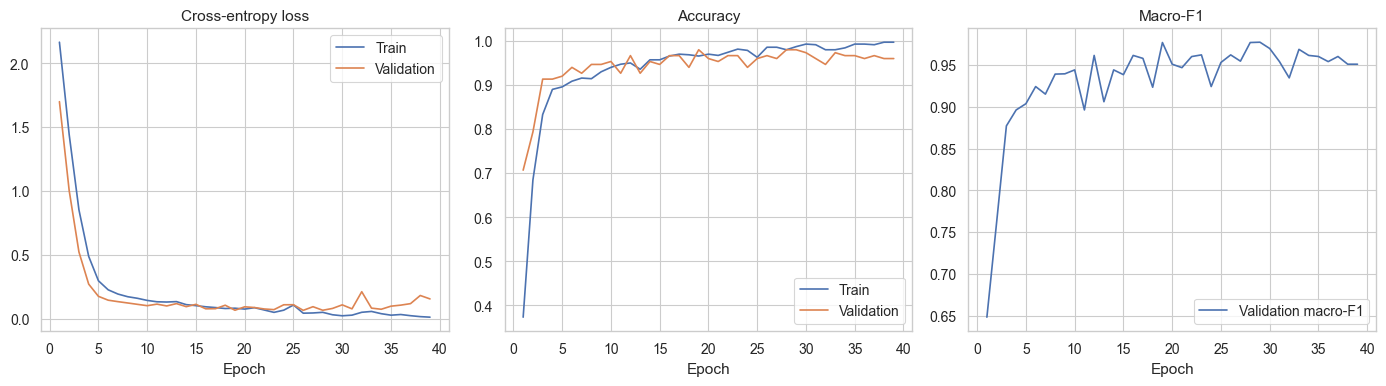

In [14]:
fig,axs=plt.subplots(1,3,figsize=(14,4))
for k,a in [('train_loss','Train'),('val_loss','Validation')]:axs[0].plot(hist.epoch,hist[k],label=a)
for k,a in [('train_accuracy','Train'),('val_accuracy','Validation')]:axs[1].plot(hist.epoch,hist[k],label=a)
axs[2].plot(hist.epoch,hist.val_macro_f1,label='Validation macro-F1')
for ax,title in zip(axs,['Cross-entropy loss','Accuracy','Macro-F1']):ax.set(xlabel='Epoch',title=title);ax.legend()
savefig('03_lstm_training_curves')

7. Final held-out test comparison (episode-level)

In [16]:
probs={'Random Forest':best_rf.predict_proba(Ate),'LSTM':infer(model,Zte)}
# sklearn may omit classes if training has no examples (not the case here); check ordering
assert np.array_equal(best_rf.classes_,np.arange(K))
def metrics(y,prob):
    pred=prob.argmax(axis=1)
    pm,rm,fm,_=precision_recall_fscore_support(y,pred,average='macro',zero_division=0)
    pw,rw,fw,_=precision_recall_fscore_support(y,pred,average='weighted',zero_division=0)
    return dict(accuracy=accuracy_score(y,pred),precision_macro=pm,recall_macro=rm,f1_macro=fm,
                precision_weighted=pw,recall_weighted=rw,f1_weighted=fw)
summary=pd.DataFrame([dict(model=name,**metrics(yte,prob)) for name,prob in probs.items()]).set_index('model')
display(summary.round(4));summary.to_csv(ROOT/'results'/'model_comparison_test.csv')
for name,prob in probs.items():
    print('\n===',name,'===\n',classification_report(yte,prob.argmax(1),target_names=classes,zero_division=0))
    pd.DataFrame(classification_report(yte,prob.argmax(1),target_names=classes,output_dict=True,zero_division=0)).T.to_csv(ROOT/'results'/f'{name.lower().replace(" ","_")}_classification_report.csv')

,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted
model,,,,,,,
Random Forest,0.9733,0.9737,0.9737,0.9737,0.9733,0.9733,0.9733
LSTM,0.9533,0.9575,0.9554,0.9556,0.9556,0.9533,0.9536



=== Random Forest ===
                        precision    recall  f1-score   support

              walking       1.00      1.00      1.00        13
    approaching_robot       1.00      1.00      1.00        12
       avoiding_robot       1.00      1.00      1.00        15
requesting_assistance       0.87      0.87      0.87        15
      object_handover       1.00      1.00      1.00        13
        object_pickup       1.00      1.00      1.00        14
      following_robot       1.00      1.00      1.00        11
             stopping       1.00      1.00      1.00        13
       greeting_robot       0.82      0.82      0.82        11
             pointing       1.00      1.00      1.00        13
         sitting_down       1.00      1.00      1.00        14
    unknown_intention       1.00      1.00      1.00         6

             accuracy                           0.97       150
            macro avg       0.97      0.97      0.97       150
         weighted avg       0

8. Research figures: confusion matrices, metric bars, per-class F1

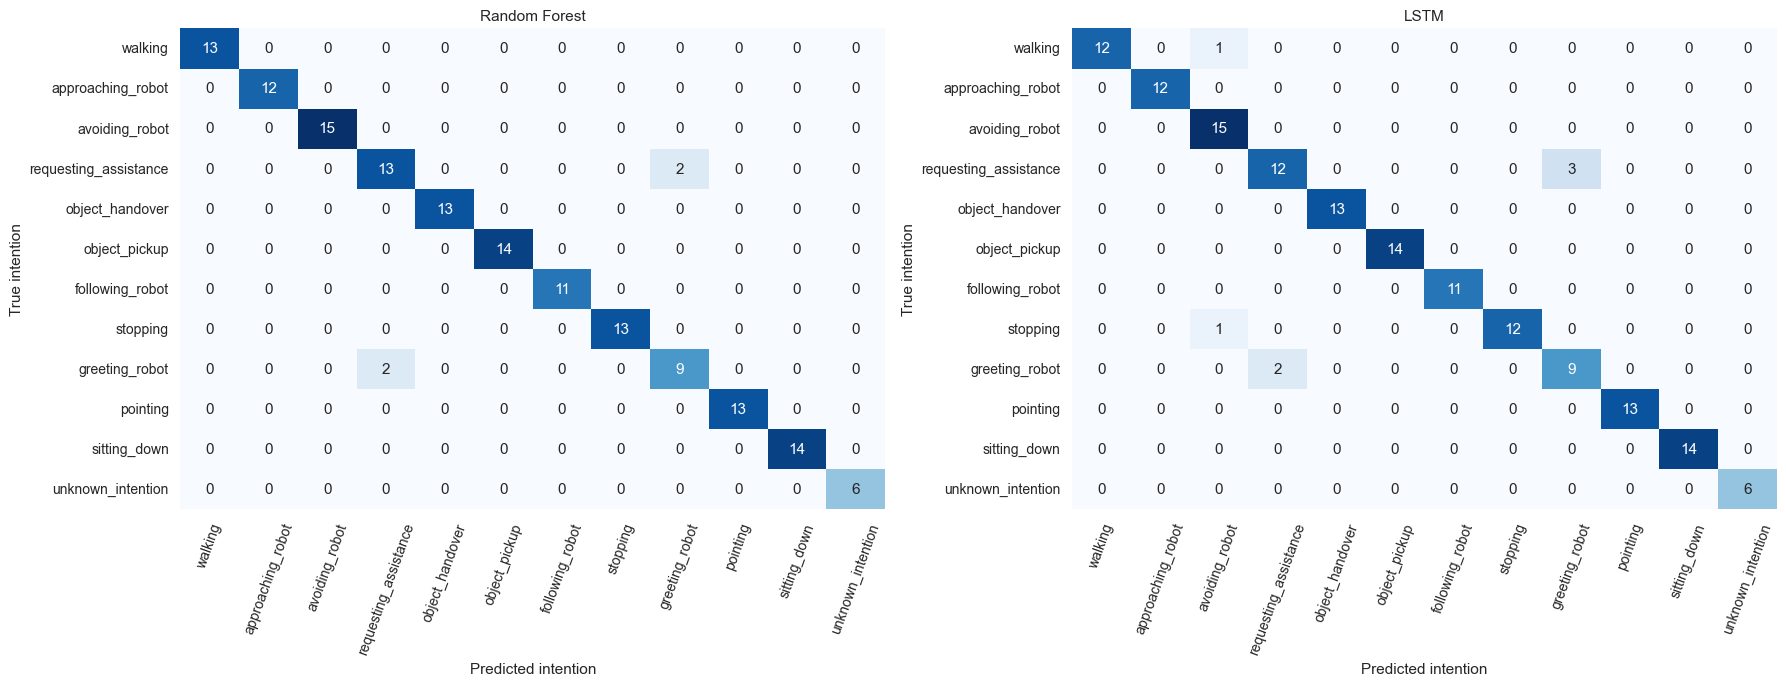

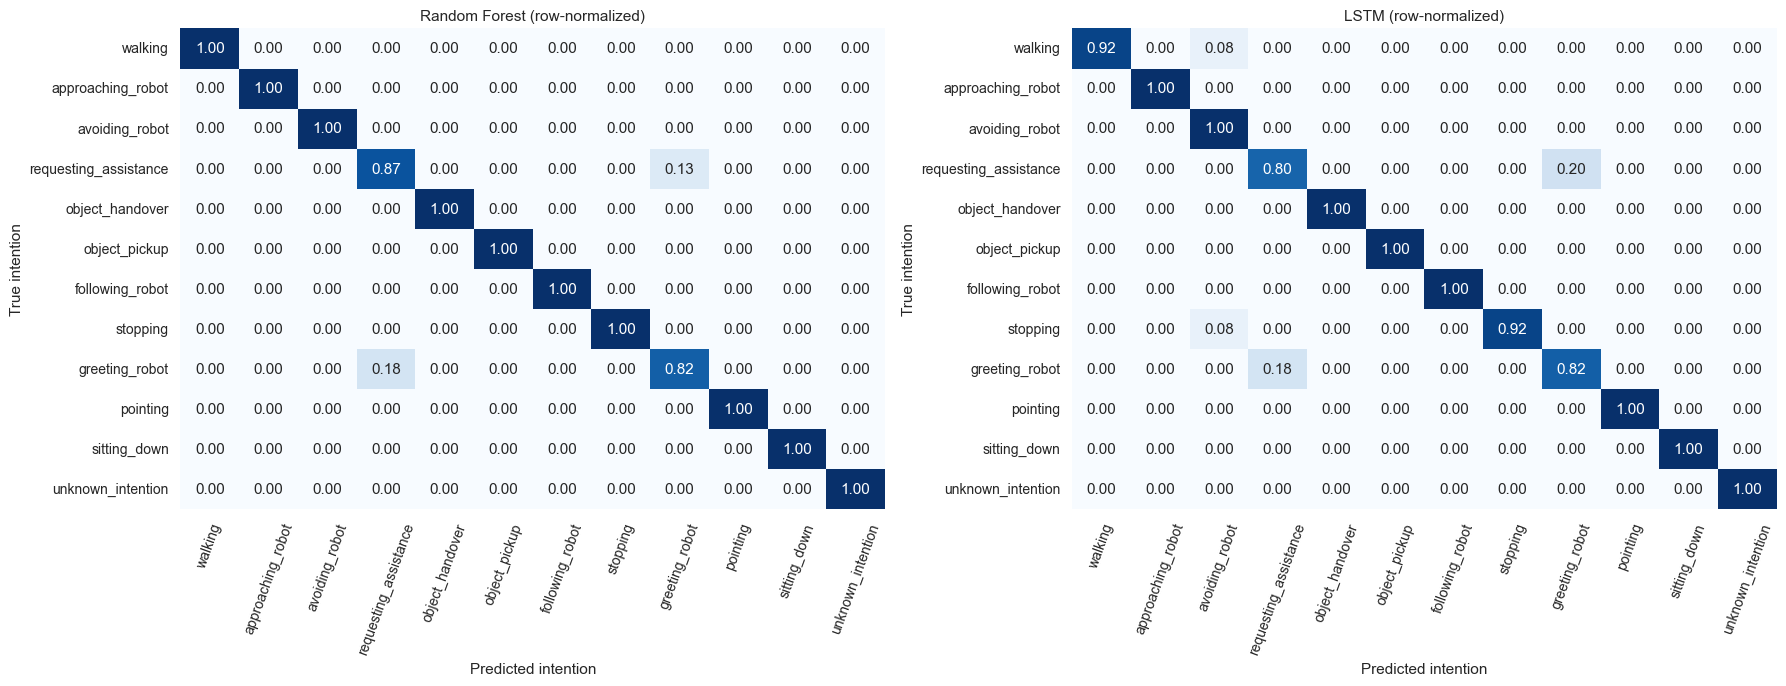

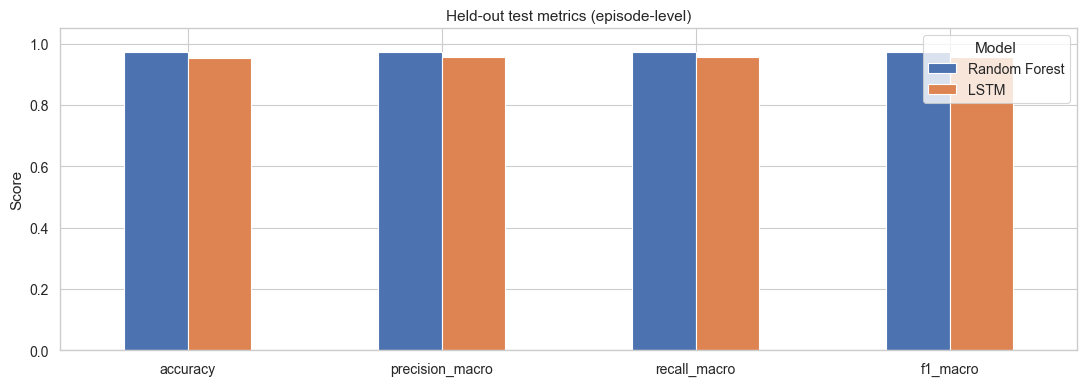

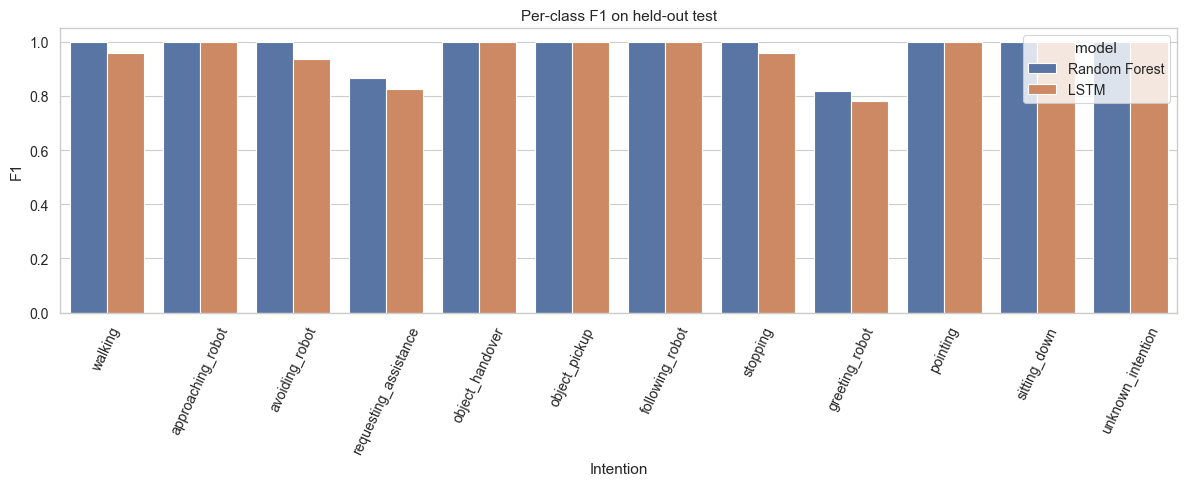

In [18]:
fig,axs=plt.subplots(1,2,figsize=(18,7))
for ax,(name,prob) in zip(axs,probs.items()):
    cm=confusion_matrix(yte,prob.argmax(1),labels=np.arange(K))
    sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=classes,yticklabels=classes,ax=ax,cbar=False)
    ax.set(title=name,xlabel='Predicted intention',ylabel='True intention');ax.tick_params(axis='x',rotation=70)
savefig('04_confusion_matrices_counts')
fig,axs=plt.subplots(1,2,figsize=(18,7))
for ax,(name,prob) in zip(axs,probs.items()):
    cm=confusion_matrix(yte,prob.argmax(1),labels=np.arange(K),normalize='true')
    sns.heatmap(cm,annot=True,fmt='.2f',cmap='Blues',vmin=0,vmax=1,xticklabels=classes,yticklabels=classes,ax=ax,cbar=False)
    ax.set(title=name+' (row-normalized)',xlabel='Predicted intention',ylabel='True intention');ax.tick_params(axis='x',rotation=70)
savefig('05_confusion_matrices_normalized')
fig,ax=plt.subplots(figsize=(11,4))
summary[['accuracy','precision_macro','recall_macro','f1_macro']].T.plot(kind='bar',ax=ax,ylim=(0,1.05),rot=0)
ax.set(ylabel='Score',title='Held-out test metrics (episode-level)');ax.legend(title='Model')
savefig('06_model_metrics_comparison')
per_class=[]
for name,prob in probs.items():
    pp,rr,ff,support=precision_recall_fscore_support(yte,prob.argmax(1),labels=np.arange(K),zero_division=0)
    for i,c in enumerate(classes):per_class.append(dict(model=name,intention=c,precision=pp[i],recall=rr[i],f1=ff[i],support=support[i]))
per_class=pd.DataFrame(per_class);per_class.to_csv(ROOT/'results'/'per_class_metrics.csv',index=False)
fig,ax=plt.subplots(figsize=(12,5))
sns.barplot(data=per_class,x='intention',y='f1',hue='model',ax=ax)
ax.set(title='Per-class F1 on held-out test',xlabel='Intention',ylabel='F1',ylim=(0,1.05));ax.tick_params(axis='x',rotation=65)
savefig('07_per_class_f1')

9. Multiclass ROC and precision–recall curves (micro-averaged)
Micro-averaging flattens one-vs-rest decisions across classes. AUCs should be interpreted cautiously for synthetic data.

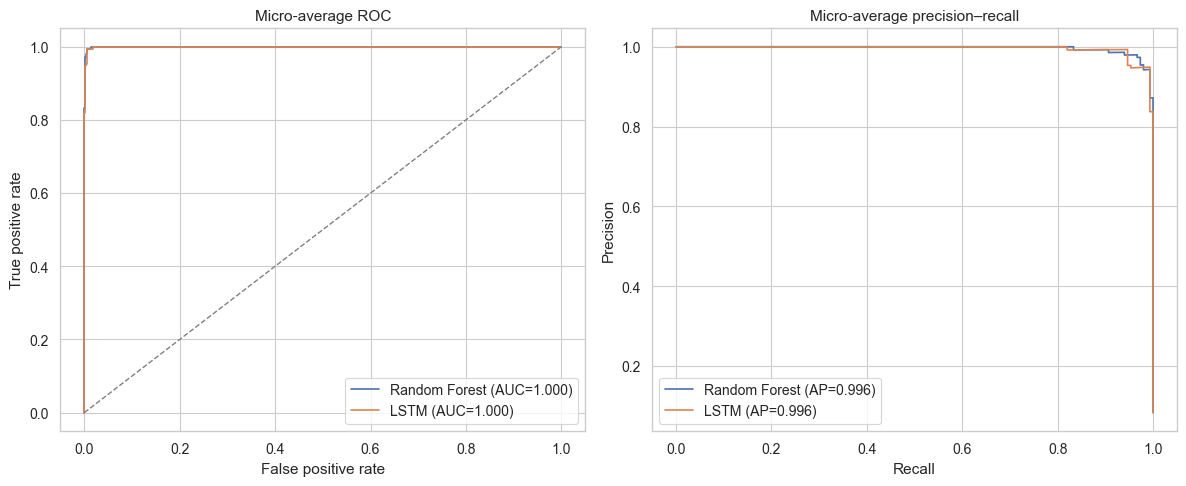

In [20]:
binary=label_binarize(yte,classes=np.arange(K))
fig,axs=plt.subplots(1,2,figsize=(12,5))
for name,prob in probs.items():
    fpr,tpr,_=roc_curve(binary.ravel(),prob.ravel());roc_auc=auc(fpr,tpr)
    precision,recall,_=precision_recall_curve(binary.ravel(),prob.ravel())
    ap=average_precision_score(binary,prob,average='micro')
    axs[0].plot(fpr,tpr,label=f'{name} (AUC={roc_auc:.3f})')
    axs[1].plot(recall,precision,label=f'{name} (AP={ap:.3f})')
axs[0].plot([0,1],[0,1],'--',color='gray',linewidth=1)
axs[0].set(title='Micro-average ROC',xlabel='False positive rate',ylabel='True positive rate')
axs[1].set(title='Micro-average precision–recall',xlabel='Recall',ylabel='Precision')
for ax in axs:ax.legend()
savefig('08_roc_pr_curves')

10. Early-intention analysis (partial sequence)
For each prefix length, retrain a separate Random Forest on prefix summaries and apply the already trained LSTM to that prefix. The LSTM has not been trained on variable-length prefixes, so this is a stress test rather than a fair optimized early-prediction benchmark.

,frames_observed,time_span_s,model,accuracy,macro_f1
0,1,0.0,Random Forest,0.726667,0.738378
1,1,0.0,LSTM,0.293333,0.263728
2,3,0.4,Random Forest,0.920000,0.923714
3,3,0.4,LSTM,0.400000,0.355356
4,5,0.8,Random Forest,0.973333,0.973898
5,5,0.8,LSTM,0.573333,0.533522
6,7,1.2,Random Forest,0.960000,0.960940
7,7,1.2,LSTM,0.806667,0.792220
8,10,1.8,Random Forest,0.973333,0.973737
9,10,1.8,LSTM,0.953333,0.955641


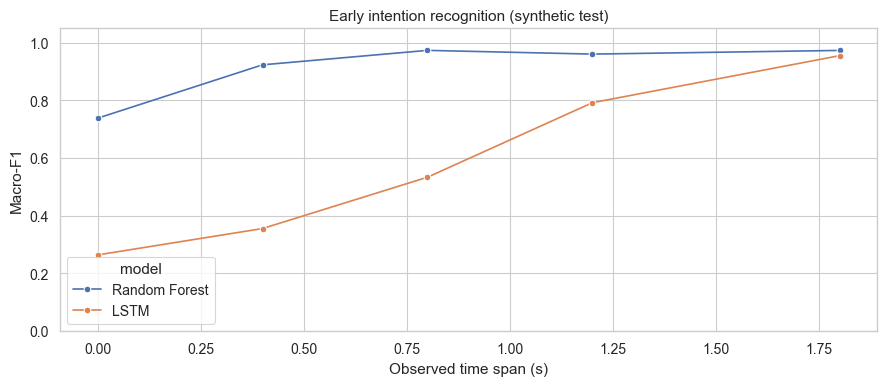

In [22]:
early=[]
for steps in [1,3,5,7,10]:
    rf=RandomForestClassifier(n_estimators=250,max_depth=best_rf.max_depth,
                              min_samples_leaf=best_rf.min_samples_leaf,
                              class_weight='balanced_subsample',random_state=SEED,n_jobs=-1)
    rf.fit(aggregate(Ztr[:,:steps]),ytr)
    rp=rf.predict(aggregate(Zte[:,:steps]))
    lp=infer(model,Zte[:,:steps]).argmax(1)
    for name,pred in [('Random Forest',rp),('LSTM',lp)]:
        early.append({'frames_observed':steps,'time_span_s':round((steps-1)*.2,1),'model':name,
                      'accuracy':accuracy_score(yte,pred),
                      'macro_f1':precision_recall_fscore_support(yte,pred,average='macro',zero_division=0)[2]})
early=pd.DataFrame(early);display(early)
early.to_csv(ROOT/'results'/'early_intention_metrics.csv',index=False)
fig,ax=plt.subplots(figsize=(9,4))
sns.lineplot(data=early,x='time_span_s',y='macro_f1',hue='model',marker='o',ax=ax)
ax.set(title='Early intention recognition (synthetic test)',xlabel='Observed time span (s)',ylabel='Macro-F1',ylim=(0,1.05))
savefig('09_early_intention')

11. Export experiment artifacts and reproducibility details

In [24]:
torch.save({'model_state_dict':model.cpu().state_dict(),'features':features,'classes':classes},ROOT/'results'/'lstm_model.pt')
import pickle
with open(ROOT/'results'/'random_forest_and_scaler.pkl','wb') as f:pickle.dump({'rf':best_rf,'scaler':scaler,'features':features},f)
metadata={'seed':SEED,'device':str(DEVICE),'features':features,'classes':classes,
          'train_episodes':len(ytr),'validation_episodes':len(yva),'test_episodes':len(yte),
          'lstm_best_val_macro_f1':float(best),'rf_best_val_macro_f1':float(best_rf_score),
          'rf_params':best_rf.get_params(),'note':'Synthetic rule-generated data; results do not validate real-world generalization.'}
(ROOT/'results'/'experiment_metadata.json').write_text(json.dumps(metadata,indent=2,default=str))
print('All plots in:',FIG.resolve());print('Metrics and models in:',(ROOT/'results').resolve())

All plots in: C:\Users\RAVI RAJ\results\figures
Metrics and models in: C:\Users\RAVI RAJ\results
